<h1>Лабораторная работа №2</h1>

<strong> Мбах Наусси Джордан Вилфри НФИмд-01-26 (1032265887)</strong>

</h2>Методы оценки статических характеристик, связанных
с распределением пользователей на плоскости </h2><br><br>
<p> Цель: </p>

<ol>
    <li>
        Ознакомление с методами оценки статических характеристик. 
    </li>
</ol>

In [1]:
#libraries
import numpy as np
import matplotlib.pyplot as plt
import math

<strong>Задание 1:</strong> Сгенерировать выборку случайных чисел размером 100 и 1000 для двух
распределений – экспоненциального и нормального. Для созданных выборок сделать
следующее:

<ol>
    <li>
        Посчитать выборочное среднее и дисперсию, сравнить с математическим
ожиданием соответствующих распределений;
    </li>
    <li>
        Посчитать 0.5 и 0.99 квантили, сравнить с соответствующими теоретическими
значениями;
    </li>
    <li>
        Построить гистограмму распределения;
    </li>
    <li>
        Построить функцию распределения случайной величины на основе выборки (на
одном графике показать функции распределения, полученные из выборок
разного размера и теоретическую);
    </li>
    <li>
        Построить плотность распределения случайной величины на основе выборки (на
одном графике показать плотности распределения, полученные из выборок
разного размера и теоретическую).
    </li>
</ol>

<p>В итоге проанализировать зависимость точности аппроксимации от количества
экспериментов.</p>

In [2]:
# Samples

exp_100 = np.random.exponential(1, 100)
exp_1000 = np.random.exponential(1, 1000)
norm_100 = np.random.normal(0, 1, 100)
norm_1000 = np.random.normal(0, 1, 1000)

In [3]:
# task 1
print(f"Exp N=100 mean={np.mean(exp_100)}, var={np.var(exp_100)}")
print(f"Exp N=1000 mean={np.mean(exp_1000)}, var={np.var(exp_1000)}")
print("Theory exp: mean=1 var=1")

print(f"\nNorm N=100 mean={np.mean(norm_100)}, var={np.var(norm_100)}")
print(f"Norm N=1000 mean={np.mean(norm_1000)}, var={np.var(norm_1000)}")
print("Theory exp: mean=0 var=1")

Exp N=100 mean=0.987919869937324, var=1.050279257525617
Exp N=1000 mean=0.9238263035393595, var=0.9166149727296511
Theory exp: mean=1 var=1

Norm N=100 mean=0.14420632928670504, var=1.028351483473971
Norm N=1000 mean=-0.021209012360694182, var=0.9860074503372023
Theory exp: mean=0 var=1


In [4]:
# task 2
print(f"Exp quantiles N=100. for P=0.5 {np.quantile(exp_100, 0.5)}, for P=0.99 {np.quantile(exp_100, 0.99)}")
print(f"Exp quantiles N=1000. for P=0.5 {np.quantile(exp_1000, 0.5)}, for P=0.99 {np.quantile(exp_1000, 0.99)}")
print (f"Theory exp quantiles: for P=0.5 {-np.log(1-0.5)}. for P=0.99 {-np.log(1-0.99)}")

print(f"\nNorm quantiles N=100. for P=0.5 {np.quantile(norm_100, 0.5)}, for P=0.99 {np.quantile(norm_100, 0.99)}")
print(f"Norm quantiles N=1000. for P=0.5 {np.quantile(norm_1000, 0.5)}, for P=0.99 {np.quantile(norm_1000, 0.99)}")
print (f"Theory Norm quantiles: for P=0.5 is 0. for P=0.99 is 2.32")

Exp quantiles N=100. for P=0.5 0.6562721766597104, for P=0.99 4.21901369963311
Exp quantiles N=1000. for P=0.5 0.591694012462581, for P=0.99 4.577607236365637
Theory exp quantiles: for P=0.5 0.6931471805599453. for P=0.99 4.605170185988091

Norm quantiles N=100. for P=0.5 0.2525876696932141, for P=0.99 2.0482511462278365
Norm quantiles N=1000. for P=0.5 0.014891967722566443, for P=0.99 2.2656445570392476
Theory Norm quantiles: for P=0.5 is 0. for P=0.99 is 2.32


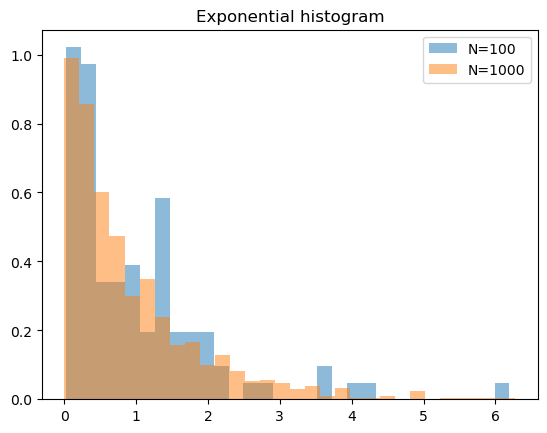

In [5]:
# task 3: histogram exp
plt.hist(exp_100, bins=30, density=True, label="N=100", alpha=0.5)
plt.hist(exp_1000, bins=30, density=True, label="N=1000", alpha=0.5)
plt.title("Exponential histogram")
plt.legend()
plt.show()

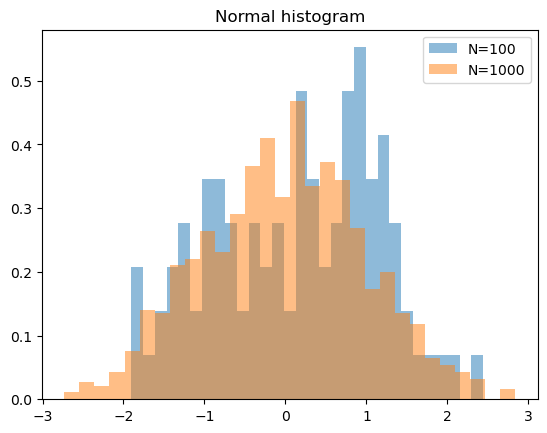

In [6]:
# task 3: histogram norm
plt.hist(norm_100, bins=30, density=True, label="N=100", alpha=0.5)
plt.hist(norm_1000, bins=30, density=True, label="N=1000", alpha=0.5)
plt.title("Normal histogram")
plt.legend()
plt.show()

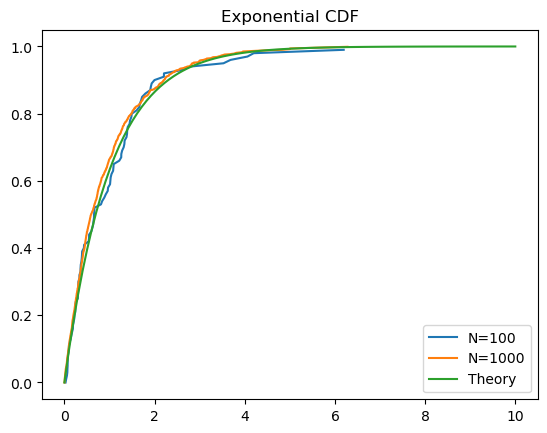

In [8]:
# task 4 функцию распределения exponential
exp_x100 = np.sort(exp_100)
exp_y100 = np.arange(0, 100)/100
exp_x1000 = np.sort(exp_1000)
exp_y1000 = np.arange(0, 1000)/1000
theory_x = np.linspace(0, 10, 100)
theory_cdf = 1- np.exp(-theory_x)

plt.plot(exp_x100, exp_y100, label="N=100")
plt.plot(exp_x1000, exp_y1000, label="N=1000")
plt.plot(theory_x, theory_cdf, label="Theory")
plt.title("Exponential CDF")
plt.legend()
plt.show()

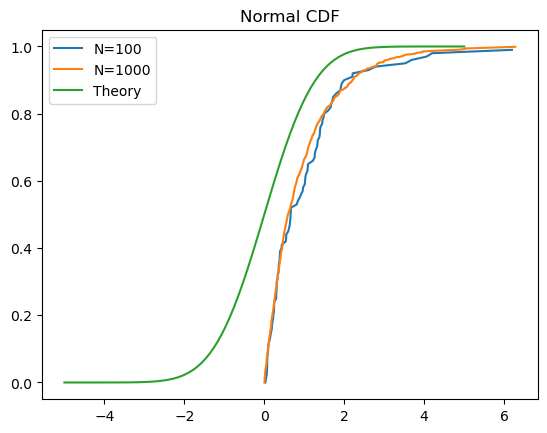

In [13]:
# task 4 функцию распределения normal
norm_x100 = np.sort(exp_100)
norm_y100 = np.arange(0, 100)/100
norm_x1000 = np.sort(exp_1000)
norm_y1000 = np.arange(0, 1000)/1000
theory_norm_x = np.linspace(-5, 5, 100)
theory_norm_cdf = [0.5 * (1 + math.erf(v / math.sqrt(2))) for v in theory_norm_x]

plt.plot(norm_x100, norm_y100, label="N=100")
plt.plot(norm_x1000, norm_y1000, label="N=1000")
plt.plot(theory_norm_x, theory_norm_cdf, label="Theory")
plt.title("Normal CDF")
plt.legend()
plt.show()

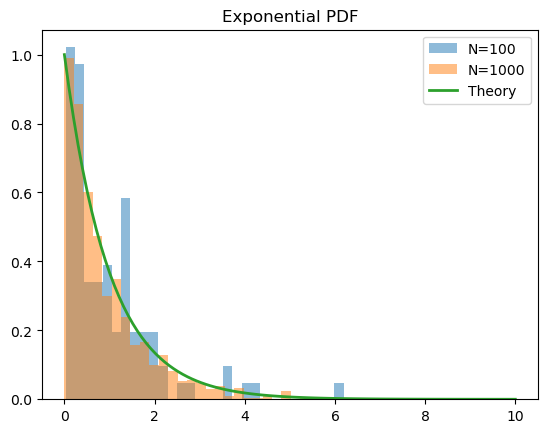

In [14]:
# task 5 плотность распределения exponential
theory_pdf = np.exp(-theory_x)
plt.hist(exp_100, bins=30, density=True, alpha=0.5, label="N=100")
plt.hist(exp_1000, bins=30, density=True, alpha=0.5, label="N=1000")
plt.plot(theory_x, theory_pdf, label="Theory", linewidth=2)
plt.title("Exponential PDF")
plt.legend()
plt.show()

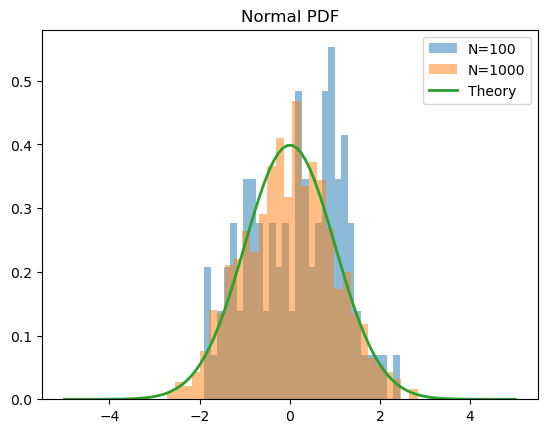

In [15]:
# task 5 плотность распределения exponential
theory_norm_pdf = (1/np.sqrt(2*np.pi)) * np.exp(-theory_norm_x ** 2 / 2)
plt.hist(norm_100, bins=30, density=True, alpha=0.5, label="N=100")
plt.hist(norm_1000, bins=30, density=True, alpha=0.5, label="N=1000")
plt.plot(theory_norm_x, theory_norm_pdf, label="Theory", linewidth=2)
plt.title("Normal PDF")
plt.legend()
plt.show()

<p>
    Для обоих распределений выборочное среднее и дисперсия приближались к теоретическим значениям при росте N с 100 до 1000: для экспоненциальной выборки среднее приближалось к 1, а дисперсия — к 1, для нормальной выборки среднее приближалось к 0, а дисперсия — к 1 (<strong>
        Exp N=100 mean=0.987919869937324, var=1.050279257525617 </br>
        Exp N=1000 mean=0.9238263035393595, var=0.9166149727296511 </br>
        Theory exp: mean=1 var=1</br>
</strong></br>
<strong>
        Norm N=100 mean=0.14420632928670504, var=1.028351483473971</br>
        Norm N=1000 mean=-0.021209012360694182, var=0.9860074503372023</br>
        Theory exp: mean=0 var=1</br>
</strong>). Та же закономерность наблюдалась для квантилей — квантили 0.5 и 0.99, посчитанные при N=1000, были ближе к теоретическим, чем при N=100. На графиках CDF и PDF эмпирическая кривая при N=1000 заметно точнее повторяла теоретическую кривую, чем кривая при N=100, которая была более неровной. Это показывает, что точность аппроксимации растёт с увеличением числа экспериментов (размера выборки), что является прямой иллюстрацией закона больших чисел.
</p>

<strong>Задание 2:</strong>

In [16]:
def random_distances(N):
    x1 = np.random.uniform(0, 10, N)
    y1 = np.random.uniform(0, 30, N)
    x2 = np.random.uniform(0, 10, N)
    y2 = np.random.uniform(0, 30, N)
    return np.sqrt((x2-x1)**2 + (y2-y1)**2)

d_100 = random_distances(100)
d_1000 = random_distances(1000)
d_10000 = random_distances(10000)

print(f"Mean distance N=100: {np.mean(d_100)}")
print(f"Mean distance N=1000: {np.mean(d_1000)}")
print(f"Mean distance N=10000: {np.mean(d_10000)}")

Mean distance N=100: 11.143943571566652
Mean distance N=1000: 10.944297555211769
Mean distance N=10000: 11.123972030481806


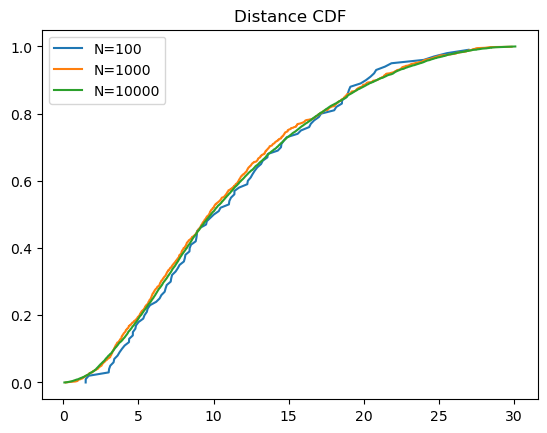

In [17]:
# CDF
for d, label in [(d_100, "N=100"), (d_1000, "N=1000"), (d_10000, "N=10000")]:
    d_sorted = np.sort(d)
    y= np.arange(0, len(d))/len(d)
    plt.plot(d_sorted, y, label=label)
plt.title("Distance CDF")
plt.legend()
plt.show()

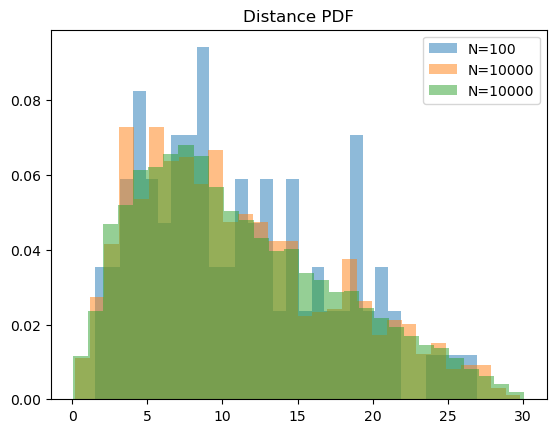

In [18]:
# PDF
plt.hist(d_100, bins=30, density=True, alpha=0.5, label="N=100")
plt.hist(d_1000, bins=30, density=True, alpha=0.5, label="N=10000")
plt.hist(d_10000, bins=30, density=True, alpha=0.5, label="N=10000")
plt.title("Distance PDF")
plt.legend()
plt.show()

<p>
    Среднее расстояние между двумя точками, равномерно распределёнными в прямоугольнике 10×30, стабилизировалось при росте N с 100 до 10000. На графике CDF кривая при N=100 была заметно ступенчатой/неровной, а кривые при N=1000 и особенно при N=10000 были намного более гладкими и почти совпадали между собой, что показывает сходимость к устойчивой форме. Тот же эффект наблюдался на графике PDF: гистограмма при N=100 имела неровные столбцы, а при N=10000 — гладкую, устойчивую форму. Поскольку для этого распределения расстояния нет простой теоретической формулы, сходимость между тремя размерами выборки сама по себе служит доказательством того, что оценка становится надёжной с ростом числа экспериментов.
</p>